# TDA Mapper graph of the training wafer maps (DBSCAN eps 2.0)

This notebook rebuilds the **training set** from `wafer_map_tda_reviewed.ipynb` (seed 42, 1,000 synthetic wafer maps), extracts the same **34 H0/H1 TDA features**, and runs KeplerMapper on them.

| Setting | Value |
|---|---|
| Features | 34 (`TDAFeatureExtractor(max_dimension=1)`), standardized |
| Lens | PCA, 2 components |
| Cover | 10 cubes, 50% overlap |
| Clusterer | `DBSCAN(eps=2.0, min_samples=3)` |

The original notebook used `eps=1.0`, which leaves about 30% of wafers (all Edge-Loc, nearly all Scratch) outside the graph. `eps=2.0` keeps every class visible. Change `EPS` in the Mapper cell to compare.

The data is synthetic, so class separation reflects the generator, not real-fab behavior.

In [1]:
# Google Colab only: install the package. On a local machine, run `pip install -e '.[notebook]'`
# from the repository root instead (see the README).
import sys
if "google.colab" in sys.modules:
    %pip install -q "wafer-map-tda[notebook] @ git+https://github.com/janhavi-giri/wafer-map-tda.git"

## 1. Imports

The generator and feature extractor come from the `wafer_map_tda` package in this repository.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from wafer_map_tda import SyntheticWaferMapGenerator, TDAFeatureExtractor

## 3. Regenerate the training data and extract features
Same seed and call order as the original notebook, so the maps are identical.

In [3]:
np.random.seed(42)
generator = SyntheticWaferMapGenerator(wafer_size=26)
wafer_maps, labels = generator.generate_dataset(n_samples=1000)
labels = np.array(labels)

tda_extractor = TDAFeatureExtractor(max_dimension=1)   # H0/H1, 34 features
X, feature_names = tda_extractor.fit_transform(wafer_maps)
print("Feature matrix:", X.shape)

Extracting TDA features from 1000 wafer maps...


Processed 100/1000 maps...


Processed 200/1000 maps...


Processed 300/1000 maps...


Processed 400/1000 maps...


...

Processed 600/1000 maps...


Processed 700/1000 maps...


Processed 800/1000 maps...


Processed 900/1000 maps...


Processed 1000/1000 maps...
Feature matrix: (1000, 34)


## 4. Mapper graph

In [4]:
import warnings
warnings.filterwarnings("ignore")
import kmapper
from kmapper import Cover
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, LabelEncoder

EPS = 2.0            # original notebook used 1.0
MIN_SAMPLES = 3
N_CUBES = 10
OVERLAP = 0.5
HTML_PATH = "tda_mapper_eps2_all_classes.html"

X_scaled = StandardScaler().fit_transform(X)

mapper = kmapper.KeplerMapper(verbose=0)
lens = mapper.project(X_scaled, projection=PCA(n_components=2, random_state=0), scaler=None)

graph = mapper.map(
    lens,
    X_scaled,
    clusterer=DBSCAN(eps=EPS, min_samples=MIN_SAMPLES),
    cover=Cover(n_cubes=N_CUBES, perc_overlap=OVERLAP),
)

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(labels)

mapper.visualize(
    graph,
    path_html=HTML_PATH,
    title=f"TDA Mapper Graph: Training Wafer Maps (seed 42, n=1000, eps={EPS:g})",
    color_values=y_encoded,
    color_function_name=["Defect class (encoded)"],
    custom_tooltips=labels,
    X=X_scaled,
    X_names=feature_names,
    lens=lens,
    lens_names=["PCA 1", "PCA 2"],
)
print("Saved", HTML_PATH)
print("Class encoding:", dict(enumerate(label_encoder.classes_)))

Saved tda_mapper_eps2_all_classes.html
Class encoding: {0: np.str_('Center'), 1: np.str_('Donut'), 2: np.str_('Edge-Loc'), 3: np.str_('Edge-Ring'), 4: np.str_('Loc'), 5: np.str_('Near-full'), 6: np.str_('None'), 7: np.str_('Random'), 8: np.str_('Scratch')}


## 5. Graph summary and per-class coverage

In [5]:
import collections
import networkx as nx

nodes, links = graph["nodes"], graph["links"]
G = nx.Graph()
G.add_nodes_from(nodes)
for a, targets in links.items():
    for b in targets:
        G.add_edge(a, b)

in_graph = {i for members in nodes.values() for i in members}
majority = {n: str(collections.Counter(labels[m]).most_common(1)[0][0]) for n, m in nodes.items()}
purity = [collections.Counter(labels[m]).most_common(1)[0][1] / len(m) for m in nodes.values()]
by_majority = collections.Counter(majority.values())

print(f"Nodes: {len(nodes)}   Edges: {G.number_of_edges()}   Components: {nx.number_connected_components(G)}")
print(f"Wafers in graph: {len(in_graph)} of {len(labels)}")
print(f"Mean node purity: {np.mean(purity):.3f}   Nodes with purity >= 0.9: {sum(p >= 0.9 for p in purity)} of {len(purity)}")

summary = pd.DataFrame({
    "wafers": [int((labels == c).sum()) for c in label_encoder.classes_],
    "in_graph": [len([i for i in np.where(labels == c)[0] if i in in_graph]) for c in label_encoder.classes_],
    "majority_nodes": [by_majority.get(str(c), 0) for c in label_encoder.classes_],
}, index=label_encoder.classes_)
summary

Nodes: 53   Edges: 95   Components: 9
Wafers in graph: 944 of 1000
Mean node purity: 0.877   Nodes with purity >= 0.9: 36 of 53


,wafers,in_graph,majority_nodes
Center,38,38,0
Donut,26,26,4
Edge-Loc,61,38,15
Edge-Ring,33,33,2
Loc,108,104,6
Near-full,20,20,1
None,586,584,13
Random,72,72,6
Scratch,56,29,6


## 6. Static preview (node size = members, color = majority class)
Open the HTML file for the interactive graph with tooltips.

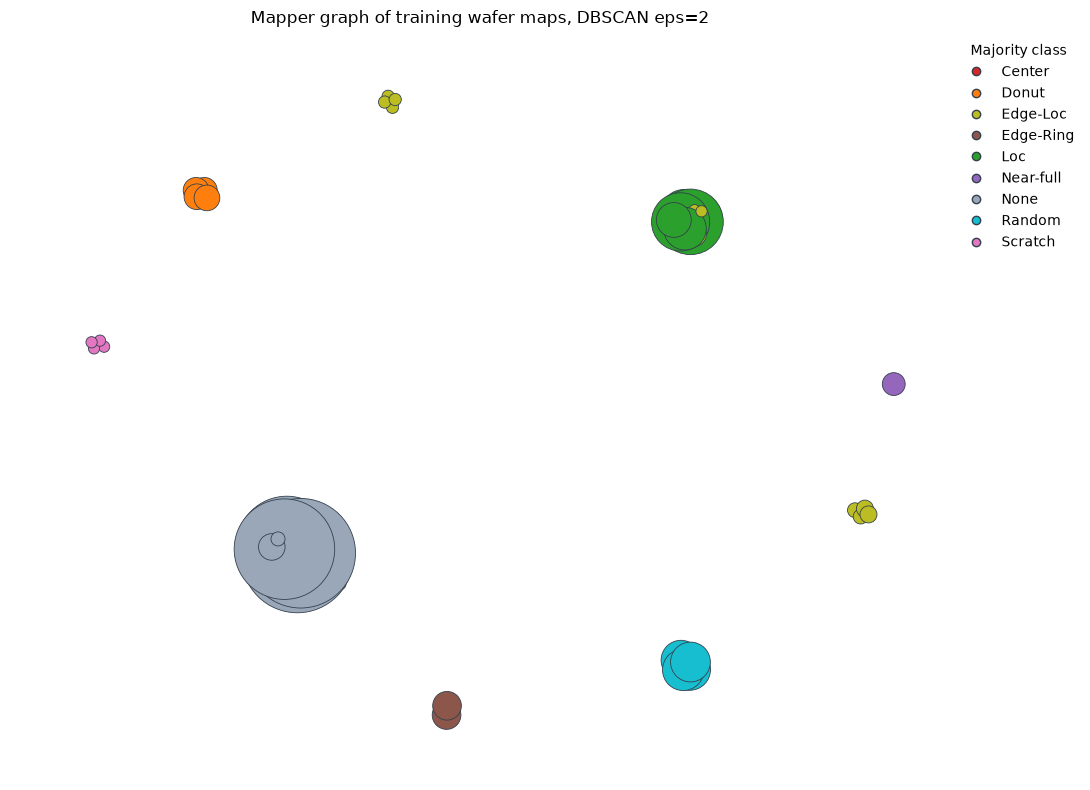

In [6]:
palette = {
    "Center": "#d62728", "Donut": "#ff7f0e", "Edge-Loc": "#bcbd22", "Edge-Ring": "#8c564b",
    "Loc": "#2ca02c", "Near-full": "#9467bd", "None": "#9aa7b8", "Random": "#17becf", "Scratch": "#e377c2",
}
pos = nx.spring_layout(G, seed=7, k=0.35, iterations=300)
node_list = list(G.nodes)

fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#c4ccd6", width=1.0)
nx.draw_networkx_nodes(
    G, pos, nodelist=node_list, ax=ax,
    node_size=[30 + 12 * len(nodes[n]) for n in node_list],
    node_color=[palette[majority[n]] for n in node_list],
    edgecolors="#33404d", linewidths=0.6,
)
ax.legend(
    handles=[plt.Line2D([], [], marker="o", ls="", color=palette[c], label=c, markeredgecolor="#33404d")
             for c in label_encoder.classes_],
    title="Majority class", loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False,
)
ax.set_title(f"Mapper graph of training wafer maps, DBSCAN eps={EPS:g}")
ax.axis("off")
plt.tight_layout()
plt.show()

## Notes
- At `eps=2.0`, all 38 Center wafers are in the graph but sit inside Loc-dominated nodes, so Center has no node of its own. Lower `EPS` to separate them, at the cost of dropping Edge-Loc and Scratch.
- The HTML loads d3 from a CDN, so it needs internet access to render.
- The Mapper cover and DBSCAN settings are the main knobs: try `N_CUBES`, `OVERLAP`, and `EPS` together.